# Two Moons, Shapiq und Probly(Ensemble)

**Imports:**



In [5]:
from __future__ import annotations

import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shapiq
import torch
from matplotlib.colors import TwoSlopeNorm
from scipy.special import xlogy
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from torch import nn

from probly.quantification import quantify
from probly.representer import representer
from probly.transformation import ensemble

# Seed configuration 
SEED = 0
N_SAMPLES = 500  # size of the Two Moons dataset
NOISE = 0.3  # label noise / overlap of the moons (0.05 in the probly example)
N_MEMBERS = 5  # ensemble size
EPOCHS = 500  # full-batch training epochs per member
LEARNING_RATE = 1e-2
N_BACKGROUND = 100  # background samples used to impute unknown features
GRID_LIMITS = ((-2.5, 3.5), (-2.0, 2.5))  # (x1 range, x2 range) for all maps
GRID_RES_MAP = 150  # resolution of the plain uncertainty maps
GRID_RES_SHAPLEY = 60  # resolution of the Shapley maps (60 x 60 = 3600 explanations)

FEATURE_NAMES = ["x1", "x2"]
NOTIONS = ("total", "aleatoric", "epistemic")

np.random.seed(SEED)
torch.manual_seed(SEED)
rng = np.random.default_rng(SEED)

**TWO MOONS** 

Two Moons mit erhöhtem Rauschen erzeugen um, damit die es einen Überlapppungsbereich gibt. 

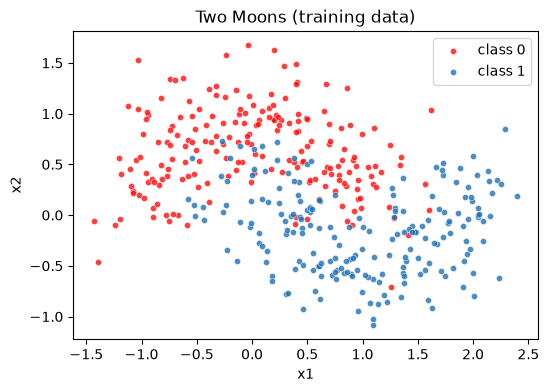

train: (400, 2), test: (100, 2)


In [7]:
X, y = make_moons(n_samples=N_SAMPLES, noise=NOISE, random_state=SEED)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED, stratify=y)


def plot_data(ax: plt.Axes, s: float = 12, alpha: float = 0.8) -> None:
    """Scatter the training data of both classes onto an axis."""
    for label, color in ((0, "#ff0e0e"), (1, "#1f71b4")):
        mask = y_train == label
        ax.scatter(
            X_train[mask, 0],
            X_train[mask, 1],
            s=s,
            c=color,
            alpha=alpha,
            edgecolor="white",
            linewidths=0.4,
            label=f"class {label}",
        )


fig, ax = plt.subplots(figsize=(6, 4))
plot_data(ax, s=20)
ax.set(title="Two Moons (training data)", xlabel="x1", ylabel="x2")
ax.legend()
plt.show()
print(f"train: {X_train.shape}, test: {X_test.shape}")

Zu sehen ist 
1. Aleatorische Unsicherheit: In der Überlappungszone
2. Empirische Unsicherheit: In den ecken eher 

**Deep Ensembly mit probly**

kleines eigenes MLP erstellen mit zwei Eingaben

In [8]:
class MLP(nn.Module):
    """Small fully connected classifier that outputs logits for two classes."""

    def __init__(self, in_features: int = 2, hidden: int = 64, out_features: int = 2) -> None:
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_features, hidden),
            nn.ReLU(),
            nn.Linear(hidden, hidden),
            nn.ReLU(),
            nn.Linear(hidden, out_features),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.net(x)


torch.manual_seed(SEED)
ensemble_model = ensemble(
    MLP(),
    num_members=N_MEMBERS,
    reset_params=True,  # fresh initialisation per member -> diversity
    predictor_type="logit_classifier",
)

# Train every member independently with plain cross-entropy (as in the probly example).
X_train_t = torch.as_tensor(X_train, dtype=torch.float32)
y_train_t = torch.as_tensor(y_train, dtype=torch.long)

ensemble_model.train()
for i, member in enumerate(ensemble_model):
    optimizer = torch.optim.Adam(member.parameters(), lr=LEARNING_RATE)
    for _ in range(EPOCHS):
        optimizer.zero_grad()
        loss = nn.functional.cross_entropy(member(X_train_t), y_train_t)
        loss.backward()
        optimizer.step()
    print(f"member {i}: final training loss = {loss.item():.3f}")
ensemble_model.eval()

member 0: final training loss = 0.142
member 1: final training loss = 0.142
member 2: final training loss = 0.148
member 3: final training loss = 0.119
member 4: final training loss = 0.127


ModuleList(
  (0-4): 5 x MLP(
    (net): Sequential(
      (0): Linear(in_features=2, out_features=64, bias=True)
      (1): ReLU()
      (2): Linear(in_features=64, out_features=64, bias=True)
      (3): ReLU()
      (4): Linear(in_features=64, out_features=2, bias=True)
    )
  )
)

Das Ensemble ist genauso gut eigentlch oder etwas besser als die einzelnen mitglieder

Für das shapiq-Spiel brauchen wir die Wahrscheinlichkeiten **jedes einzelnen Mitglieds** (nicht nur den Mittelwert),
denn die Uneinigkeit der Mitglieder *ist* die epistemische Unsicherheit. 

In [ ]:
@torch.no_grad()
def member_probabilities(model: nn.Module, X: np.ndarray) -> np.ndarray:

    x = torch.as_tensor(np.asarray(X), dtype=torch.float32)
    return np.stack([torch.softmax(member(x), dim=-1).cpu().numpy() for member in model])

In [10]:
probs_test = member_probabilities(ensemble_model, X_test)
member_acc = (probs_test.argmax(axis=-1) == y_test).mean(axis=1)
ensemble_acc = (probs_test.mean(axis=0).argmax(axis=-1) == y_test).mean()
print("test accuracy per member:", np.round(member_acc, 3))
print(f"test accuracy ensemble:   {ensemble_acc:.3f}")

test accuracy per member: [0.89 0.9  0.89 0.85 0.87]
test accuracy ensemble:   0.900


Das Modell hat die Struktur der Monde gelernt, fehler liegen bei der Überlappungszone 


**Unsicherheiten mit probly**

offizielle pipeline von probly verwenden
Ziel ist es zu sehen wo im Eingabebereich das Esemble unsicher ist, später schau ich auch mit shapiq

drei karten gezeichnet 

In [11]:
rep = representer(ensemble_model)


@torch.no_grad()
def probly_uncertainty(X: np.ndarray) -> dict[str, np.ndarray]:
    """Quantify total, aleatoric and epistemic uncertainty with probly's default decomposition."""
    decomposition = quantify(rep.represent(torch.as_tensor(np.asarray(X), dtype=torch.float32)))
    return {notion: torch.as_tensor(getattr(decomposition, notion)).detach().cpu().numpy() for notion in NOTIONS}

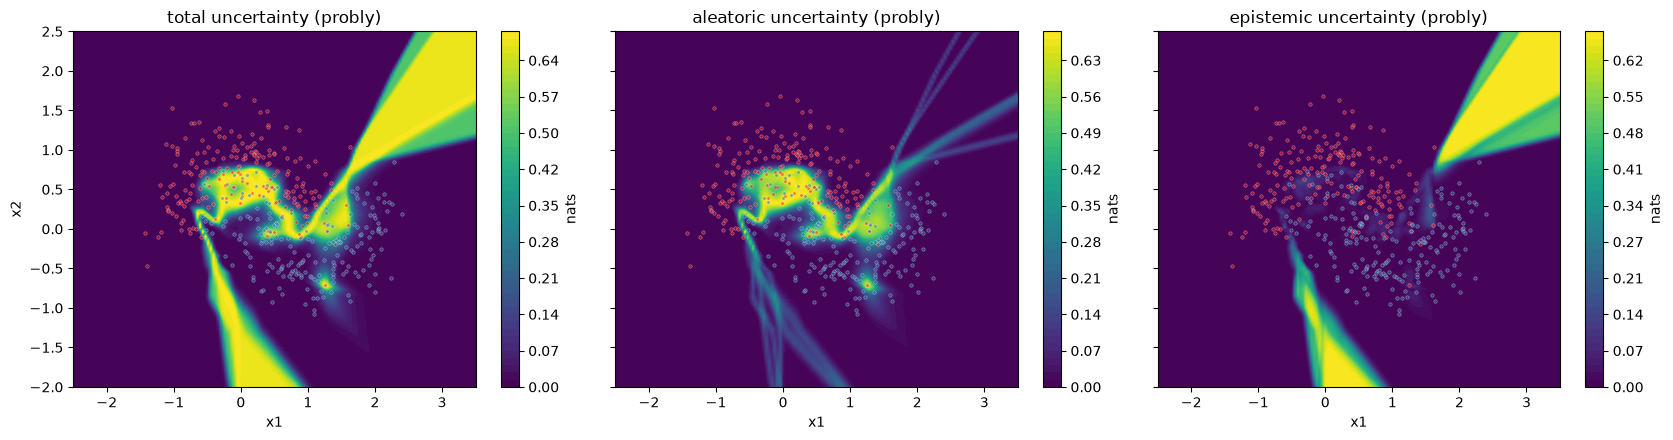

In [12]:
def make_grid(resolution: int) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """Return meshgrid coordinates and the flattened grid points of shape (resolution**2, 2)."""
    (x_lo, x_hi), (y_lo, y_hi) = GRID_LIMITS
    xx, yy = np.meshgrid(np.linspace(x_lo, x_hi, resolution), np.linspace(y_lo, y_hi, resolution))
    return xx, yy, np.c_[xx.ravel(), yy.ravel()]


def plot_uncertainty_map(ax: plt.Axes, values: np.ndarray, label: str = "nats") -> None:
    """Draw an uncertainty map on the fine grid (tiny negative round-off values are clipped to 0)."""
    values = np.clip(values.reshape(xx.shape), 0.0, None)
    contour = ax.contourf(xx, yy, values, levels=np.linspace(0.0, values.max() + 1e-12, 50), cmap="viridis")
    plot_data(ax, s=6, alpha=0.5)
    ax.figure.colorbar(contour, ax=ax, label=label, format="%.2f")


xx, yy, grid = make_grid(GRID_RES_MAP)
grid_unc = probly_uncertainty(grid)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5), sharey=True)
for ax, notion in zip(axes, NOTIONS, strict=True):
    plot_uncertainty_map(ax, grid_unc[notion])
    ax.set(title=f"{notion} uncertainty (probly)", xlabel="x1")
axes[0].set_ylabel("x2")
plt.tight_layout()
plt.show()

Bei der AU wurde die Annahme bestätigt 
Bei der Überlappngszone, sagen alle 5, dass sie sich einig sind , dass es unklar ist

Frage: Muss man eigentlich immer prüfen dass die rechnung Richtig ist, also NumPy und probly ausgaben vergleichen?

In [13]:
def entropy(p: np.ndarray) -> np.ndarray:
    """Shannon entropy in nats over the last axis (0 * log 0 := 0)."""
    return -np.sum(xlogy(p, p), axis=-1)


def decompose_uncertainty(member_probs: np.ndarray) -> dict[str, np.ndarray]:
    """Entropy-based decomposition TU = AU + EU for an ensemble.

    Args:
        member_probs: Array of shape (n_members, ..., n_classes).

    Returns:
        Dict with 'total', 'aleatoric' and 'epistemic' arrays of shape (...).
    """
    total = entropy(member_probs.mean(axis=0))
    aleatoric = entropy(member_probs).mean(axis=0)
    return {"total": total, "aleatoric": aleatoric, "epistemic": total - aleatoric}

**SHAPIQ GAME**

EnsembleUncertaintygame

In [14]:
class EnsembleUncertaintyGame(shapiq.Game):
    """Cooperative game whose value is the ensemble's uncertainty given a subset of features.

    Players are the input features. For a coalition S, the features in S are fixed to the
    explained point x and the remaining features are taken from background samples
    (marginal imputation). For every ensemble member, the predictive distribution is
    averaged over the background samples, yielding the member's prediction when only x_S
    is known. The entropy decomposition is then applied to these marginal predictions.

    Args:
        model: Trained probly ensemble.
        x: The point to explain, shape (n_features,).
        background: Background data used for imputation, shape (n_background, n_features).
        notion: Which uncertainty to explain: 'total', 'aleatoric' or 'epistemic'.
    """

    def __init__(self, model: nn.Module, x: np.ndarray, background: np.ndarray, notion: str = "epistemic") -> None:
        if notion not in NOTIONS:
            msg = f"notion must be one of {NOTIONS}, got {notion!r}"
            raise ValueError(msg)
        self.model = model
        self.x = np.asarray(x, dtype=float).reshape(-1)
        self.background = np.asarray(background, dtype=float)
        self.notion = notion
        super().__init__(
            n_players=self.x.shape[0],
            normalize=False,  # keep v(empty) visible as baseline_value
            player_names=FEATURE_NAMES[: self.x.shape[0]],
        )

    def coalition_uncertainties(self, coalitions: np.ndarray) -> dict[str, np.ndarray]:
        """Compute TU, AU and EU for a batch of coalitions of shape (n_coalitions, n_features)."""
        coalitions = np.asarray(coalitions, dtype=bool)
        n_coalitions, n_features = coalitions.shape
        n_background = self.background.shape[0]
        # Known features come from x, unknown ones from the background:
        # result has shape (n_coalitions, n_background, n_features).
        x_imputed = np.where(coalitions[:, None, :], self.x[None, None, :], self.background[None, :, :])
        probs = member_probabilities(self.model, x_imputed.reshape(-1, n_features))
        probs = probs.reshape(probs.shape[0], n_coalitions, n_background, -1)
        # Average distributions over the background per member: p_m(y | x_S).
        marginal_probs = probs.mean(axis=2)  # (n_members, n_coalitions, n_classes)
        return decompose_uncertainty(marginal_probs)

    def value_function(self, coalitions: np.ndarray) -> np.ndarray:
        """Return the chosen uncertainty notion for every coalition."""
        return self.coalition_uncertainties(coalitions)[self.notion]


def explain_point(x: np.ndarray, notion: str, index: str = "SV", order: int = 1) -> shapiq.InteractionValues:
    """Exactly compute Shapley values (or interactions) of one uncertainty notion at x."""
    game = EnsembleUncertaintyGame(ensemble_model, x, background, notion)
    return shapiq.ExactComputer(game)(index=index, order=order)

**Idee**

1. Unsicherheit als kooperatives Spiel für shapiq formuliert
2. Spieler = Merkmale x1 und x2
3. Wert einer Koalition v(S) = Unsicherheit des Ensembles, wenn nur die Merkmale in S bekannt sind
4. 4 Koalitionen: ∅, {x1}, {x2}, {x1, x2}

In [21]:
background = X_train[rng.choice(len(X_train), size=N_BACKGROUND, replace=False)]

# Quick look at a single game: values of all four coalitions at the origin.
demo_game = EnsembleUncertaintyGame(ensemble_model, np.array([0.0, 0.0]), background, "epistemic")
demo_coalitions = np.array([[0, 0], [1, 0], [0, 1], [1, 1]], dtype=bool)
print(demo_game)
print("EU of coalitions {}, {x1}, {x2}, {x1,x2}:", np.round(demo_game(demo_coalitions), 4))

EnsembleUncertaintyGame(2 players, normalize=False, normalization_value=0.0, precomputed=False)
EU of coalitions {}, {x1}, {x2}, {x1,x2}: [0.0002 0.0008 0.0018 0.0023]


**Ergebnis lesen**

φ > 0: Merkmal erhöht die Unsicherheit
φ < 0: Merkmal senkt die Unsicherheit, liefert also Information
v(∅) + φ_x1 + φ_x2 = Unsicherheit am Punkt

### Was sind die konkreten Ergebnisse aus probly und shapiq?

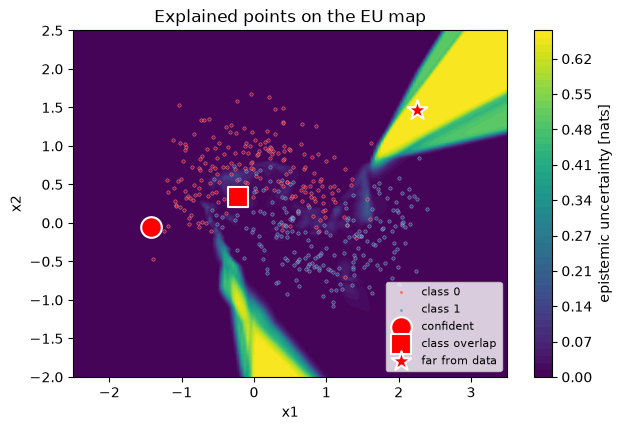

In [16]:
train_unc = probly_uncertainty(X_train)
points = {
    "confident": X_train[np.argmin(train_unc["total"])],
    "class overlap": X_train[np.argmax(train_unc["aleatoric"])],
    "far from data": grid[np.argmax(grid_unc["epistemic"])],
}
markers = {"confident": "o", "class overlap": "s", "far from data": "*"}

fig, ax = plt.subplots(figsize=(7, 4.5))
plot_uncertainty_map(ax, grid_unc["epistemic"], label="epistemic uncertainty [nats]")
for name, x in points.items():
    ax.scatter(
        *x, marker=markers[name], s=220, c="red", edgecolor="white", linewidths=1.5, label=name, zorder=5, clip_on=False
    )
ax.set(title="Explained points on the EU map", xlabel="x1", ylabel="x2")
ax.legend(loc="lower right", fontsize=8)
plt.show()

In [17]:
explanations = {name: {notion: explain_point(x, notion) for notion in NOTIONS} for name, x in points.items()}

rows = []
for name, per_notion in explanations.items():
    for notion, sv in per_notion.items():
        rows.append(
            {
                "point": name,
                "notion": notion,
                "v(empty)": sv.baseline_value,
                "phi_x1": sv[(0,)],
                "phi_x2": sv[(1,)],
                "v(all) = v(empty) + sum(phi)": sv.baseline_value + sv[(0,)] + sv[(1,)],
            }
        )
pd.DataFrame(rows).round(3)

,point,notion,v(empty),phi_x1,phi_x2,v(all) = v(empty) + sum(phi)
0,confident,total,0.691,-0.645,-0.046,0.000
1,confident,aleatoric,0.691,-0.644,-0.047,0.000
2,confident,epistemic,0.001,-0.002,0.001,0.000
3,class overlap,total,0.691,-0.007,0.008,0.693
4,class overlap,aleatoric,0.691,-0.013,0.008,0.686
5,class overlap,epistemic,0.001,0.006,0.000,0.007
6,far from data,total,0.691,0.029,-0.047,0.673
7,far from data,aleatoric,0.691,-0.310,-0.381,0.000
8,far from data,epistemic,0.001,0.338,0.334,0.673


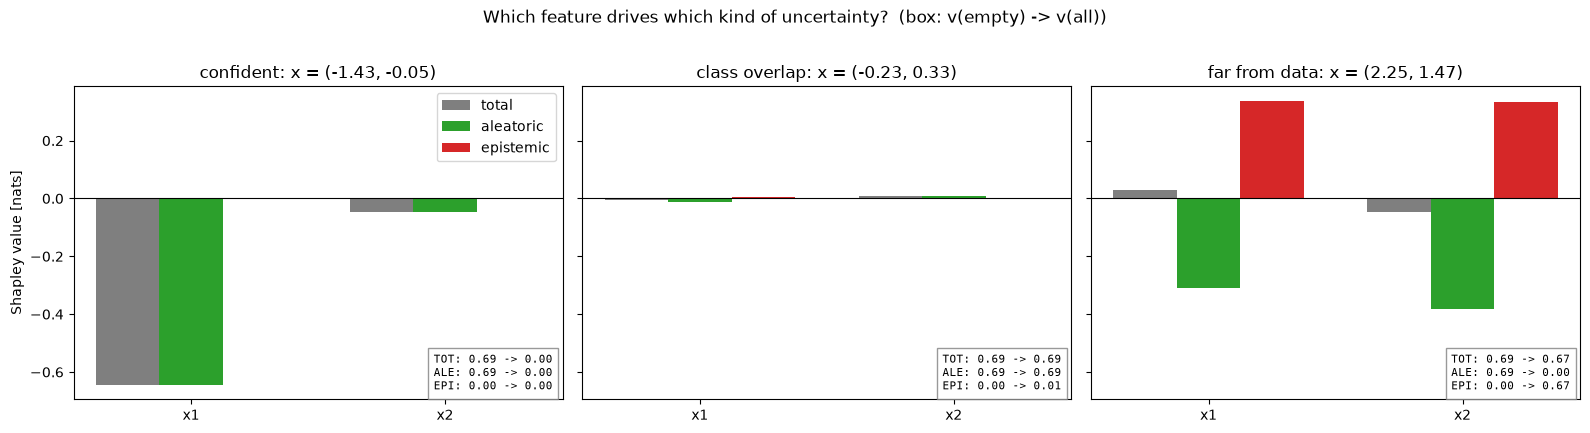

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2), sharey=True)
width = 0.25
colors = {"total": "#7f7f7f", "aleatoric": "#2ca02c", "epistemic": "#d62728"}
for ax, (name, per_notion) in zip(axes, explanations.items(), strict=True):
    for j, notion in enumerate(NOTIONS):
        values = [per_notion[notion][(i,)] for i in range(len(FEATURE_NAMES))]
        ax.bar(np.arange(len(FEATURE_NAMES)) + (j - 1) * width, values, width, label=notion, color=colors[notion])
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_xticks(range(len(FEATURE_NAMES)), FEATURE_NAMES)
    # Show where each explanation starts (v(empty)) and ends (v(all)).
    summary = "\n".join(
        f"{notion[:3].upper()}: {per_notion[notion].baseline_value:.2f} -> "
        f"{per_notion[notion].baseline_value + sum(per_notion[notion][(i,)] for i in range(len(FEATURE_NAMES))):.2f}"
        for notion in NOTIONS
    )
    ax.text(
        0.98,
        0.02,
        summary,
        transform=ax.transAxes,
        ha="right",
        va="bottom",
        fontsize=8,
        family="monospace",
        bbox={"facecolor": "white", "alpha": 0.8, "edgecolor": "grey"},
    )
    x = points[name]
    ax.set_title(f"{name}: x = ({x[0]:.2f}, {x[1]:.2f})")
axes[0].set_ylabel("Shapley value [nats]")
axes[0].legend(loc="upper right")
plt.suptitle("Which feature drives which kind of uncertainty?  (box: v(empty) -> v(all))", y=1.02)
plt.tight_layout()
plt.show()

**Interpretation:**

1. „confident“ bei (−1.43, −0.05), am linken Ende des roten Monds
TU und AU: 0.69 → 0.00. Das Modell wird völlig sicher.
Fast der ganze Beitrag kommt von x1 (≈ −0.64), x2 trägt kaum bei (≈ −0.05).
Erklärung: Bei x1 = −1.43 gibt es in den Daten nur rote Punkte, der blaue Mond beginnt erst weiter rechts. x1 allein verrät also schon die Klasse. x2 = −0.05 kommt dagegen bei beiden Klassen vor und ist allein wenig aussagekräftig.
EU ≈ 0: Die Mitglieder sind sich einig.
2. „class overlap“ bei (−0.23, 0.33), im Überlappungsbereich
TU und AU: 0.69 → 0.69. Die Unsicherheit bleibt maximal.
Alle Shapley-Werte ≈ 0: Auch wenn man beide Merkmale kennt, wird das Modell nicht sicherer.
EU: 0.00 → 0.01, also praktisch null: Die Mitglieder sind sich einig, dass es 50:50 steht.
Das ist die Signatur aleatorischer Unsicherheit: Die Merkmale liefern keine Information, weil an dieser Stelle beide Klassen gleich häufig vorkommen. Die leeren Balken sind kein Fehler, sondern das Ergebnis.
3. „far from data“ bei (2.25, 1.47), im oberen EU-Keil
TU: 0.69 → 0.67. Die Gesamtunsicherheit ändert sich kaum.
Aber ihre Art kehrt sich komplett um:
AU: 0.69 → 0.00. Beide Merkmale senken sie (x1 ≈ −0.31, x2 ≈ −0.38): Jedes einzelne Mitglied wird sehr sicher.
EU: 0.00 → 0.67. Beide Merkmale erhöhen sie fast gleich stark (x1 ≈ +0.34, x2 ≈ +0.33): Die sicheren Mitglieder widersprechen sich.
Die Merkmale wandeln aleatorische in epistemische Unsicherheit um. Ohne Wissen über den Punkt ist das Modell aus „Rauschgründen“ unsicher, mit Wissen aus „Wissensgründen“.
Warum tragen beide gleich viel bei? x1 = 2.25 allein ist unauffällig, dort liegen viele blaue Punkte. x2 = 1.47 allein auch, dort liegt die Spitze des roten Monds. Erst die Kombination ergibt eine Stelle ohne Trainingsdaten. Genau dann teilen Shapley-Werte den Effekt halb-halb auf. Das deutet auf eine starke Interaktion hin. Prüfen könnt ihr das mit der k-SII-Tabelle: φ_x1x2 sollte dort groß sein.


Kernaussagen
Die Zerlegung macht den Unterschied. Würde man nur die totale Unsicherheit erklären (graue Balken), sähe man beim fernen Punkt fast nichts. Erst die getrennte Erklärung von AU und EU zeigt, was wirklich passiert. Das ist der Mehrwert eures Projekts.
Alle drei Erwartungen aus den Daten haben sich bestätigt: sicher im Mond, aleatorisch in der Überlappung, epistemisch in der leeren Region.
Die Rechnung ist konsistent: Grau = Grün + Rot bei jedem Merkmal, z. B. bei x1 im dritten Panel: −0.31 + 0.34 ≈ 0.03. Das ist TU = AU + EU, übertragen auf die Shapley-Werte (Check 4 in Abschnitt 8).


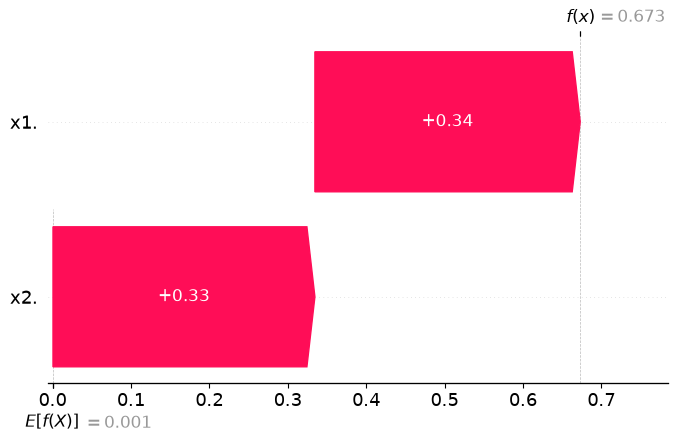

In [19]:
explanations["far from data"]["epistemic"].plot_waterfall(feature_names=FEATURE_NAMES)

Unnötig aber ein plot von shapiq 

### Was ist die Interaktion von $x_1$ und $x_2$

In [20]:
rows = []
for name, x in points.items():
    for notion in ("aleatoric", "epistemic"):
        ksii = explain_point(x, notion, index="k-SII", order=2)
        rows.append(
            {
                "point": name,
                "notion": notion,
                "phi_x1": ksii[(0,)],
                "phi_x2": ksii[(1,)],
                "phi_x1x2": ksii[(0, 1)],
            }
        )
pd.DataFrame(rows).round(3)

,point,notion,phi_x1,phi_x2,phi_x1x2
0,confident,aleatoric,-0.691,-0.094,0.094
1,confident,epistemic,-0.001,0.002,-0.002
2,class overlap,aleatoric,-0.032,-0.012,0.040
3,class overlap,epistemic,0.006,0.000,-0.000
4,far from data,aleatoric,-0.533,-0.605,0.447
5,far from data,epistemic,0.025,0.020,0.627


**Die Shapley-Werte zeigen fern der Daten, dass x1 und x2 gleich viel zur epistemischen Unsicherheit beitragen. Die Interaktionsanalyse mit k-SII zeigt den eigentlichen Grund: Über 90 % der Unsicherheit entstehen erst durch die Kombination beider Merkmale. Jeder einzelne Wert kommt in den Trainingsdaten vor, die Kombination aber nie. Das Ensemble erkennt also fehlendes Wissen über die gemeinsame Verteilung der Merkmale**

## Shapley Unsicherheitskarten 

Nun will ich alle Punkte erklären


In [22]:
xx_s, yy_s, grid_s = make_grid(GRID_RES_SHAPLEY)
map_notions = ("aleatoric", "epistemic")
shapley_maps = {notion: np.zeros((len(grid_s), len(FEATURE_NAMES))) for notion in map_notions}

start = time.perf_counter()
for k, x in enumerate(grid_s):
    for notion in map_notions:
        sv = explain_point(x, notion)
        shapley_maps[notion][k] = [sv[(i,)] for i in range(len(FEATURE_NAMES))]
print(f"Explained {len(grid_s)} points x {len(map_notions)} notions in {time.perf_counter() - start:.1f} s")

Explained 3600 points x 2 notions in 11.7 s


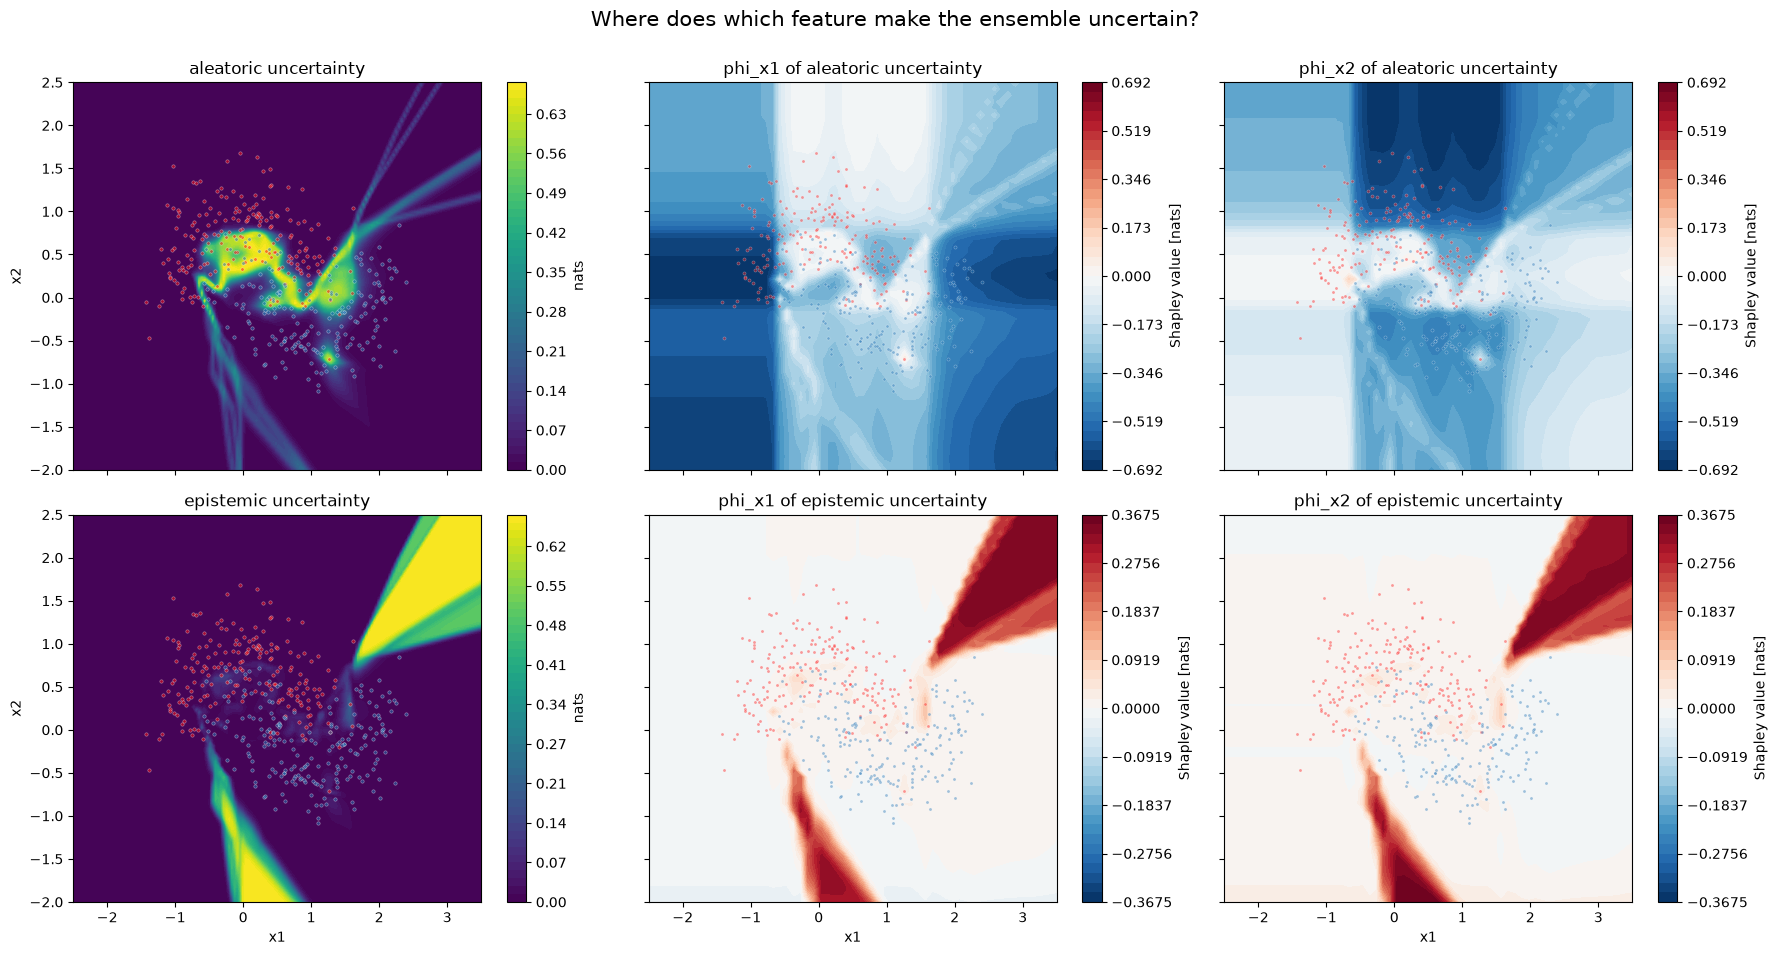

In [23]:
fig, axes = plt.subplots(2, 3, figsize=(18, 9.5), sharex=True, sharey=True)
for row, notion in enumerate(map_notions):
    # Column 0: the uncertainty itself (probly).
    ax = axes[row, 0]
    plot_uncertainty_map(ax, grid_unc[notion])
    ax.set_title(f"{notion} uncertainty")

    # Columns 1-2: Shapley values with a shared, symmetric colour scale.
    limit = float(np.abs(shapley_maps[notion]).max())
    norm = TwoSlopeNorm(vmin=-limit, vcenter=0.0, vmax=limit)
    levels = np.linspace(-limit, limit, 41)
    for i, feature in enumerate(FEATURE_NAMES):
        ax = axes[row, i + 1]
        contour = ax.contourf(
            xx_s,
            yy_s,
            shapley_maps[notion][:, i].reshape(xx_s.shape),
            levels=levels,
            cmap="RdBu_r",
            norm=norm,
        )
        plot_data(ax, s=5, alpha=0.4)
        fig.colorbar(contour, ax=ax, label="Shapley value [nats]")
        ax.set_title(f"phi_{feature} of {notion} uncertainty")

for ax in axes[-1]:
    ax.set_xlabel("x1")
for ax in axes[:, 0]:
    ax.set_ylabel("x2")
plt.suptitle("Where does which feature make the ensemble uncertain?", fontsize=15, y=1.0)
plt.tight_layout()
plt.show()

Eine kompakte Zusammenfassung der Karten: **Welches Merkmal dominiert die epistemische Unsicherheit wo?**
(Farbe = Merkmal mit dem größeren $|\phi|$: lila = $x_1$, grün = $x_2$; Farbintensität = wie groß die
EU-Attribution dort überhaupt ist. Weiß = keine nennenswerte epistemische Unsicherheit.)

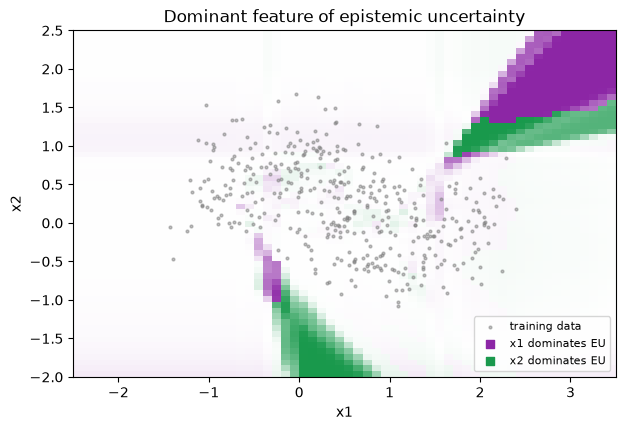

In [24]:
eu_phi = shapley_maps["epistemic"]
dominant = np.argmax(np.abs(eu_phi), axis=1).reshape(xx_s.shape)  # 0 -> x1, 1 -> x2
strength = np.abs(eu_phi).sum(axis=1).reshape(xx_s.shape)
strength = strength / strength.max()

color_x1, color_x2 = np.array([0.55, 0.15, 0.65]), np.array([0.1, 0.6, 0.3])  # purple / green
rgb = np.where(dominant[..., None] == 0, color_x1, color_x2)
image = 1.0 - strength[..., None] * (1.0 - rgb)  # blend from white to the feature colour

fig, ax = plt.subplots(figsize=(7, 4.5))
(x_lo, x_hi), (y_lo, y_hi) = GRID_LIMITS
ax.imshow(image, origin="lower", extent=(x_lo, x_hi, y_lo, y_hi), aspect="auto")
ax.scatter(X_train[:, 0], X_train[:, 1], s=4, c="grey", alpha=0.5, label="training data")
ax.scatter([], [], marker="s", c=[color_x1], label="x1 dominates EU")
ax.scatter([], [], marker="s", c=[color_x2], label="x2 dominates EU")
ax.legend(loc="lower right", fontsize=8)
ax.set(title="Dominant feature of epistemic uncertainty", xlabel="x1", ylabel="x2")
plt.show()

## 10. Fazit, Grenzen, Ausblick

**Unsere Beobachtungen** *(nach dem Ausführen ausfüllen – Leitfragen):*
- Punkt *sicher*: Sind die Shapley-Werte negativ (Merkmale *liefern* Information)? Welches Merkmal mehr?
- Punkt *Überlappung*: Wird die Unsicherheit hauptsächlich als **AU** erklärt? Wie groß ist $\phi_{x_1x_2}$?
- Punkt *fern der Daten*: Wird sie hauptsächlich als **EU** erklärt – und trägt das Merkmal, das „aus dem
  Datenbereich herausragt“, den größten Teil?
- Shapley-Karten: Wo dominiert $x_1$, wo $x_2$? Passt das zur Geometrie der Monde?

**Was wir gebaut haben:** ein `shapiq.Game`, das die Unsicherheitszerlegung eines probly-Ensembles als
Wertfunktion nutzt, inklusive vier bestandener Korrektheitschecks und Karten, die Vorhersageunsicherheit und
ihre Ursachen nebeneinander zeigen.

**Grenzen (ehrlich benennen):**
- *Marginale Imputation* kombiniert $x_S$ mit beliebigen Hintergrundwerten – auch zu Punkten, die es in den Daten
  nie gäbe (Two Moons ist stark korreliert). Das kann $v(S)$ für kleine Koalitionen verzerren.
  Abhilfe: bedingte Imputation (shapiq hat z. B. `GaussianCopulaImputer`) oder Watson-et-al.-artige bedingte
  Verteilungen.
- *Nur 2 Merkmale:* gut zum Visualisieren und exakten Rechnen, aber trivial im Vergleich zu echten Tabellendaten.
- *ReLU-Netze* extrapolieren linear; die EU fern der Daten hängt deshalb stark von der Ensemble-Diversität ab.

**Nächste Schritte:**
1. Rauschmerkmale anhängen (Ground Truth: deren $\phi \approx 0$) → mehr Spieler, Approximatoren aus shapiq.
2. Variante „erst Unsicherheit, dann mitteln“ implementieren und vergleichen.
3. Dasselbe Game mit MC-Dropout aus probly (Masken pro Punkt festhalten!).
4. Fallstudie auf einem echten Tabellendatensatz.

**Literatur:** Watson et al. (2023), *Explaining Predictive Uncertainty with Information Theoretic Shapley Values*;
Lakshminarayanan et al. (2017), *Simple and Scalable Predictive Uncertainty Estimation using Deep Ensembles*.